![Banner](../../../../Images/Banner/05_geostat/07_simulation.png)

# SNESIM: Single Normal Equation Simulation (`SNESIM`)

**Dataset:** a synthetic three-facies fluvial system: floodplain, channel sand, and levees that always separate the two. A 200 × 200 training image, a separate 100 × 100 "true" field, 80 wells, and a blurred, noisy "seismic" secondary variable.

**Library:** `geolattice.geostatistics`: `SNESIM`, `snesim`, `tau_model`, with `channel_training_image`, `pattern_histogram`, `pattern_histogram_distance` and `connectivity` for building and checking (module `geolattice.geostatistics.mps.snesim`; GPU engine `geolattice.geostatistics.gpu.mps_gpu`)

**Before this notebook:** [Multiple-point statistics overview](05_07_08_mps.ipynb), which compares SNESIM with Direct Sampling and SIS, and [sequential indicator simulation](05_07_03_sisim.ipynb).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [The single normal equation](#the-single-normal-equation)
    - 2.2 [Templates and the pattern table](#templates-and-the-pattern-table)
    - 2.3 [Data-event reduction](#data-event-reduction)
    - 2.4 [Multiple grids](#multiple-grids)
    - 2.5 [Servosystem and target proportions](#servosystem-and-target-proportions)
    - 2.6 [Soft data: the tau model](#soft-data-the-tau-model)
    - 2.7 [The GPU engine](#the-gpu-engine)
    - 2.8 [The algorithm](#the-algorithm)
3. [Python Setup](#python-setup)
4. [A Three-Facies Fluvial Training Image](#a-three-facies-fluvial-training-image)
5. [The Template](#the-template)
6. [Multiple Grids](#multiple-grids-1)
7. [Data-Event Reduction: `min_replicates`](#data-event-reduction-min_replicates)
8. [Proportions: Servosystem and Target Proportions](#proportions-servosystem-and-target-proportions)
9. [Conditioning to Wells](#conditioning-to-wells)
10. [Soft Data and the Tau Model](#soft-data-and-the-tau-model)
11. [Visualization of Uncertainty](#visualization-of-uncertainty)
    - 11.1 [Animated display of realizations](#animated-display-of-realizations)
    - 11.2 [Facies probability and entropy maps](#facies-probability-and-entropy-maps)
12. [CPU vs GPU Timing](#cpu-vs-gpu-timing)
13. [Summary and Conclusions](#summary-and-conclusions)
    - 13.1 [Choosing the options](#choosing-the-options)
14. [References](#references)

***
## Overview

SNESIM (Strebelle, 2002) was the first practical multiple-point simulator, and it is still the reference algorithm for categorical MPS. It simulates facies one node at a time, like sequential indicator simulation, but replaces indicator kriging with a **lookup**. The probability of each facies given the surrounding simulated nodes is read from the frequencies of the same configuration in a **training image** (TI). A preliminary scan stores every pattern of the TI, so each lookup is fast, and a **multigrid** scheme lets a small template capture large structures.

| Object | What it does |
|---|---|
| `SNESIM(training_image, n_template, search_radius, n_multigrid, min_replicates, servo, target_proportions, tau, use_gpu)` | The simulator. `fit(grid, df, x, y, cat, soft=None)` places hard data and optional soft probabilities; `simulate(nsim, seed)` and `simulate_lattice` draw realizations. `n_patterns_`, `categories_`, `target_proportions_` and `lattice_` describe the fit. |
| `snesim(...)` | One-call wrapper. |
| `tau_model(p_prior, p_ti, p_soft, tau)` | Combines TI and soft probabilities. |

This notebook takes SNESIM apart parameter by parameter on a three-facies fluvial system whose truth is known:

* **floodplain** (background);
* **channel** sand;
* **levees** bordering the channels, so that channel never touches floodplain directly.

That last rule makes it easy to see when the simulation produces patterns the TI never shows. The notebook measures:

* how the template, multigrid and `min_replicates` shape the realizations;
* how the servosystem and target proportions trade proportions against pattern fidelity;
* how wells and a seismic-like soft variable condition the result;
* how the tau model's exponents weigh the two information sources.

***
## Theory

### The single normal equation

Let $S(\mathbf{u}) \in \{s_1, \dots, s_K\}$ be the facies and $I_k(\mathbf{u}) = \mathbf{1}[S(\mathbf{u}) = s_k]$ its indicators. At node $\mathbf{u}$, the **data event** is the set of informed nodes around it,

$$
d_n = \{S(\mathbf{u} + \mathbf{h}_\alpha) = s_{k_\alpha},\ \alpha = 1, \dots, n\}.
$$

Indicator kriging estimates $P(S(\mathbf{u}) = s_k \mid d_n)$ as a weighted sum of the $n$ indicators, using only two-point covariances. Guardiano & Srivastava (1993) instead used **one** indicator for the whole data event, $D = \prod_\alpha I_{k_\alpha}(\mathbf{u} + \mathbf{h}_\alpha)$, which is 1 when the configuration occurs. Simple kriging of $I_k(\mathbf{u})$ from this single datum has a single normal equation:

$$
\lambda\, \operatorname{Var}(D) = \operatorname{Cov}(I_k, D)
\;\;\Longrightarrow\;\;
P^*(s_k \mid d_n) = p_k + \lambda\,(1 - E[D]) = \frac{P(S(\mathbf{u}) = s_k,\, d_n)}{P(d_n)} ,
$$

which is exactly Bayes' rule, the conditional probability. Its two ingredients are **multiple-point** statistics that no variogram contains, and they are read from the training image by counting replicates:

$$
P(s_k \mid d_n) \approx \frac{c_k(d_n)}{c(d_n)}, \qquad c(d_n) = \sum_k c_k(d_n),
$$

where $c_k(d_n)$ is the number of TI locations where the data event occurs with $s_k$ at the centre.

### Templates and the pattern table

The data event is taken on a fixed **template** $\tau_n = \{\mathbf{h}_1, \dots, \mathbf{h}_n\}$: the `n_template` offsets nearest the centre within `search_radius` cells, ordered by distance (then by angle). Before simulating, the TI is scanned **once** per grid level. Every template configuration found is stored with the counts $c_k$ of its centre categories. Strebelle stored these in a search tree; GeoLattice uses the equivalent **list** of unique patterns, as in IMPALA (Straubhaar et al., 2011). `n_patterns_` reports how many unique patterns each level holds.

At simulation time, the node's data event, with its informed template positions only, is matched against the list. Patterns that agree at every informed position contribute their counts. Template positions outside the TI never match.

### Data-event reduction

Large data events are rare in a finite TI. If fewer than `min_replicates` stored patterns match, the **farthest** informed node is dropped and the count is repeated, until enough replicates are found. All prefixes are counted in one filtering pass.

* **Small `min_replicates`** keeps more conditioning nodes, so continuity is better, at the risk of probabilities estimated from very few replicates.
* **Large values** (GSLIB-style, around 10-20) make the probabilities more stable, but drop the outer nodes that carry the long-range structure.

### Multiple grids

A template of 40 nodes in a radius of 8 cells cannot see structures 50 cells long. With `n_multigrid` $= G$, simulation runs on nested grids of spacing $2^{G-1}, \dots, 2, 1$ cells, and on grid $g$ the template is stretched to $2^g \tau_n$. The coarse grids, simulated first, place the large structures with a wide but sparse template, and finer grids fill in details conditioned on them. Each level has its own pattern table, scanned on the TI with the stretched template. Hard data are copied temporarily to the nearest coarse-grid node, so the coarse structure honours them too.

### Servosystem and target proportions

Proportions in SNESIM realizations can drift away from the target $\pi_k$ (`target_proportions`, default the TI's). The **servosystem** corrects each conditional probability with the proportions $\hat\pi_k$ simulated so far:

$$
p_k' = \max\!\left(0,\; p_k + \frac{\mu}{1 - \mu}\,(\pi_k - \hat\pi_k)\right), \quad \text{then renormalized}, \qquad \mu = \texttt{servo} \in [0, 1) .
$$

$\mu = 0$ switches it off, and $\mu \to 1$ forces the proportions. The correction is **additive**, so it can raise a category whose TI probability is 0 in that data event, creating a pattern the TI never shows. How often this happens depends on how far the proportions drift (Section 8). With target proportions different from the TI's, the servosystem is the only lever that moves the realizations toward the target.

### Soft data: the tau model

With soft probabilities $P(s_k \mid y(\mathbf{u}))$ from a secondary variable $y$ (`fit(..., soft=...)`, one row per node, columns in `categories_` order), SNESIM combines them with the TI probability through the **tau model** (Journel, 2002). In terms of probability *distances* $x = (1 - P)/P$, with $x_0$ from the prior (target proportions):

$$
\frac{x}{x_0} = \left(\frac{x_{\mathrm{TI}}}{x_0}\right)^{\tau_1} \left(\frac{x_{\text{soft}}}{x_0}\right)^{\tau_2},
\qquad
P(s_k \mid d_n, y) = \frac{1}{1 + x},
$$

renormalized over categories. With $\tau = (1, 1)$ this is the *permanence of ratios*: the soft data change the odds by the same factor whatever the TI says. That amounts to conditional independence of the two sources given the facies.

* $\tau_2 > 1$ trusts the soft data more, and $\tau_2 < 1$ discounts them (for example when they are redundant with the TI).
* $\tau_1 = 0$ ignores the TI, and $\tau_2 = 0$ the soft data.

The soft mean also becomes the default target proportion.

### The GPU engine

With `use_gpu=True`, all realizations advance in **lockstep**. At each step one fused CUDA kernel matches every realization's data event against the pattern table, applies the reduction, tau model and servosystem, and draws the categories. The host draws the paths and uniform numbers in the CPU engine's order, so **GPU realizations equal CPU realizations**. Limits: `n_template` ≤ 64 and at most 16 categories.

### The algorithm

1. Build the template; for each grid level, scan the TI and store the unique patterns with their centre counts.
2. For each realization:
    1. place the hard data;
    2. for each grid level, coarse to fine:
        1. visit the uninformed level nodes in random order;
        2. read the data event on the stretched template;
        3. reduce it until at least `min_replicates` patterns match;
        4. compute $P(s_k \mid d_n)$ from the counts; combine with soft data (tau model); apply the servosystem;
        5. draw a category.

***
## Python Setup

`SNESIM(..., use_gpu=False|'auto'|True)`. The GPU engine gives the same realizations as the CPU engine (checked in Section 12), so the runs use `use_gpu=USE_GPU`.

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from IPython.display import HTML, display
from scipy.ndimage import binary_dilation, gaussian_filter

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import (
    SNESIM,
    channel_training_image,
    connectivity,
    pattern_histogram,
    pattern_histogram_distance,
    snesim,
    tau_model,
)
from geolattice.geostatistics.utils.backend import CUPY_AVAILABLE, cupy_gpu_usable

print("pygstat version:", pygstat.__version__)
USE_GPU = cupy_gpu_usable()
if USE_GPU:
    import cupy as cp
    name = cp.cuda.runtime.getDeviceProperties(0)["name"]
    print("GPU (CuPy)      :", name.decode() if isinstance(name, bytes) else name)
else:
    print("CuPy            :", "installed, but cannot run a kernel here" if CUPY_AVAILABLE else "not installed")
print(f"use_gpu         : {USE_GPU}")

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")

pygstat version: 0.3.44
GPU (CuPy)      : NVIDIA RTX A5500 Laptop GPU
use_gpu         : True


***
## A Three-Facies Fluvial Training Image

Sinuous channels from `channel_training_image` are surrounded by a two-cell **levee** (a binary dilation), in a **floodplain**. By construction, channel (1) and floodplain (0) never touch: there is always levee (2) between them. The truth is a separate 100 × 100 image from the same generator.

TI proportions   : {'floodplain': 0.806, 'channel': 0.104, 'levee': 0.091}
TI contacts      : floodplain-levee 2896, channel-levee 2990, floodplain-channel 0 (forbidden)


TI channel connectivity at 30 cells along x: 0.94


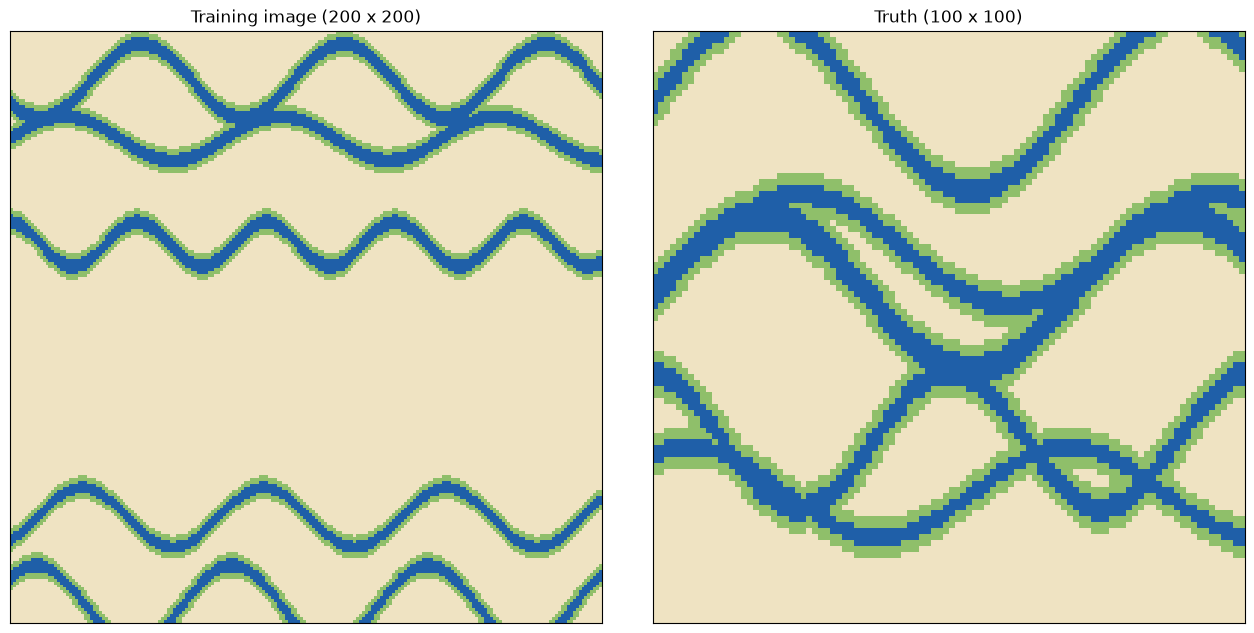

In [2]:
FACIES = ["floodplain", "channel", "levee"]
CMAP = ListedColormap(["#efe3c2", "#1f5fa8", "#8fbf6a"])


def fluvial(n, seed):
    ch = channel_training_image(n, n, n_channels=5, width=4.0, seed=seed).astype(bool)
    levee = binary_dilation(ch, iterations=2) & ~ch
    return np.where(ch, 1.0, np.where(levee, 2.0, 0.0))


def contacts(img):
    img = np.asarray(img)
    M = np.zeros((3, 3))
    for a, b in [(img[1:, :], img[:-1, :]), (img[:, 1:], img[:, :-1])]:
        ok = a != b
        np.add.at(M, (a[ok].astype(int), b[ok].astype(int)), 1)
    return M + M.T


def show(ax, img, title, wells_df=None):
    ax.imshow(np.asarray(img).T, origin="lower", cmap=CMAP, vmin=-0.5, vmax=2.5, interpolation="nearest")
    if wells_df is not None:
        ax.scatter(wells_df.X, wells_df.Y, c=[["#7a5c00", "red", "darkgreen"][int(f)] for f in wells_df.f], s=14,
                   edgecolors="w", linewidths=0.4)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


TI = fluvial(200, 0)
TRUTH = fluvial(100, 7)
NX = NY = 100
gx, gy = np.meshgrid(np.arange(NX, dtype=float), np.arange(NY, dtype=float), indexing="ij")
grid = np.column_stack([gx.ravel(), gy.ravel()])
truth = TRUTH.ravel()
M_ti = contacts(TI)
print("TI proportions   :", {f: round(float(np.mean(TI == k)), 3) for k, f in enumerate(FACIES)})
print(f"TI contacts      : floodplain-levee {M_ti[0, 2]:.0f}, channel-levee {M_ti[1, 2]:.0f}, "
      f"floodplain-channel {M_ti[0, 1]:.0f} (forbidden)")
PH_TI = pattern_histogram(TI, 3)
CONN_TI = connectivity(TI, 1, 30, 0)[-1]
print(f"TI channel connectivity at 30 cells along x: {CONN_TI:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 6.3))
show(axes[0], TI, "Training image (200 x 200)")
show(axes[1], TRUTH, "Truth (100 x 100)")
plt.tight_layout()
plt.show()

Every run below is scored with the same diagnostics:

* **forbidden contacts:** floodplain-channel cell edges per realization (0 in the TI);
* **3 × 3 pattern-histogram distance** to the TI (0 = identical);
* **channel connectivity** at 30 cells along x (TI value above);
* **facies proportions.**

`evaluate` runs SNESIM unconditionally on the 100 × 100 lattice and computes them.

In [3]:
def diagnostics(reals):
    r = np.asarray(reals)
    return {"forbidden FP-CH edges": np.mean([contacts(x)[0, 1] for x in r]),
            "pattern dist. (3x3)": np.mean([pattern_histogram_distance(PH_TI, pattern_histogram(x, 3)) for x in r]),
            "channel connectivity @30": np.nanmean([connectivity(x, 1, 30, 0)[-1] for x in r]),
            **{f"prop. {f}": np.mean(r == k) for k, f in enumerate(FACIES)}}


def evaluate(label, nsim=8, seed=1, **kw):
    sim = SNESIM(TI, use_gpu=USE_GPU, **kw).fit(grid)
    t0 = time.perf_counter()
    reals = sim.simulate_lattice(nsim=nsim, seed=seed)
    sec = time.perf_counter() - t0
    return {"setting": label, "seconds": sec, "patterns per level": sim.n_patterns_, **diagnostics(reals)}, reals


ref_row = {"setting": "training image", **diagnostics(TI[None, :100, :100]),
           "pattern dist. (3x3)": 0.0, "channel connectivity @30": CONN_TI,
           **{f"prop. {f}": np.mean(TI == k) for k, f in enumerate(FACIES)}}

***
## The Template

The template holds the `n_template` offsets nearest the centre within `search_radius`. The private helper `_template` is used here only to draw it. Larger templates capture larger patterns and store more of them, at a higher cost per lookup. All runs use `servo=0` so that only the template changes.

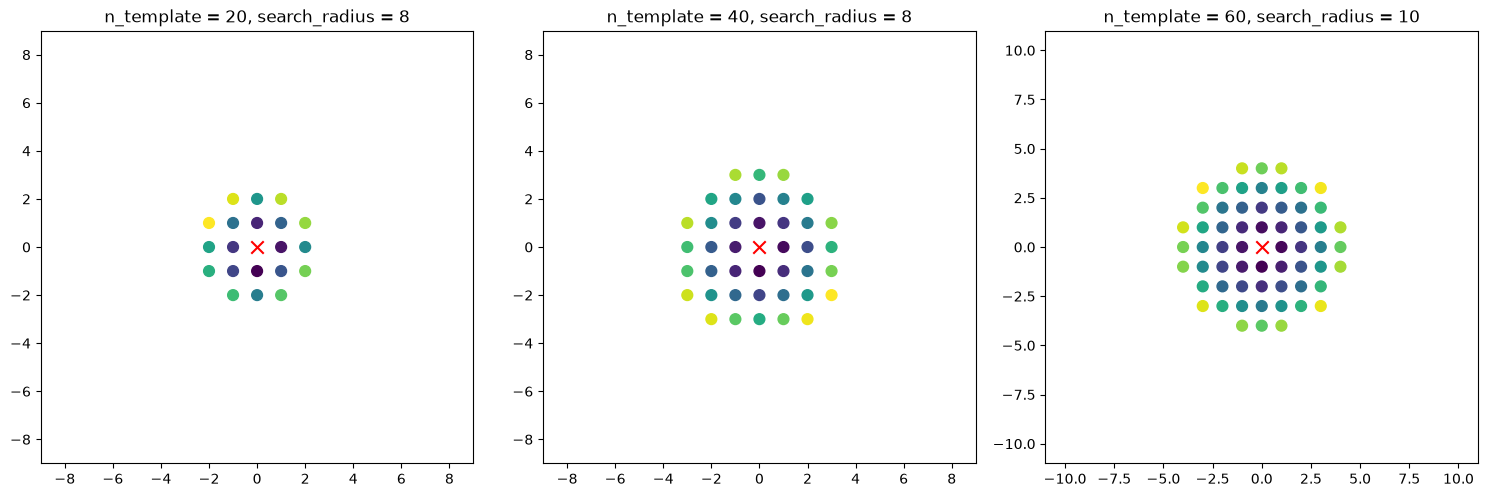

,seconds,patterns per level,forbidden FP-CH edges,pattern dist. (3x3),channel connectivity @30,prop. floodplain,prop. channel,prop. levee
setting,,,,,,,,
"n_template=20, radius=8",0.434,"[1057, 1810, 5816, 11702]",4.750,0.090,0.886,0.822,0.093,0.085
"n_template=40, radius=8",1.169,"[3428, 5470, 15076, 23801]",2.625,0.110,0.757,0.784,0.114,0.101
"n_template=60, radius=10",1.983,"[6064, 9337, 21883, 29493]",2.375,0.111,0.855,0.794,0.110,0.096
training image,NaN,NaN,0.000,0.000,0.937,0.806,0.104,0.091


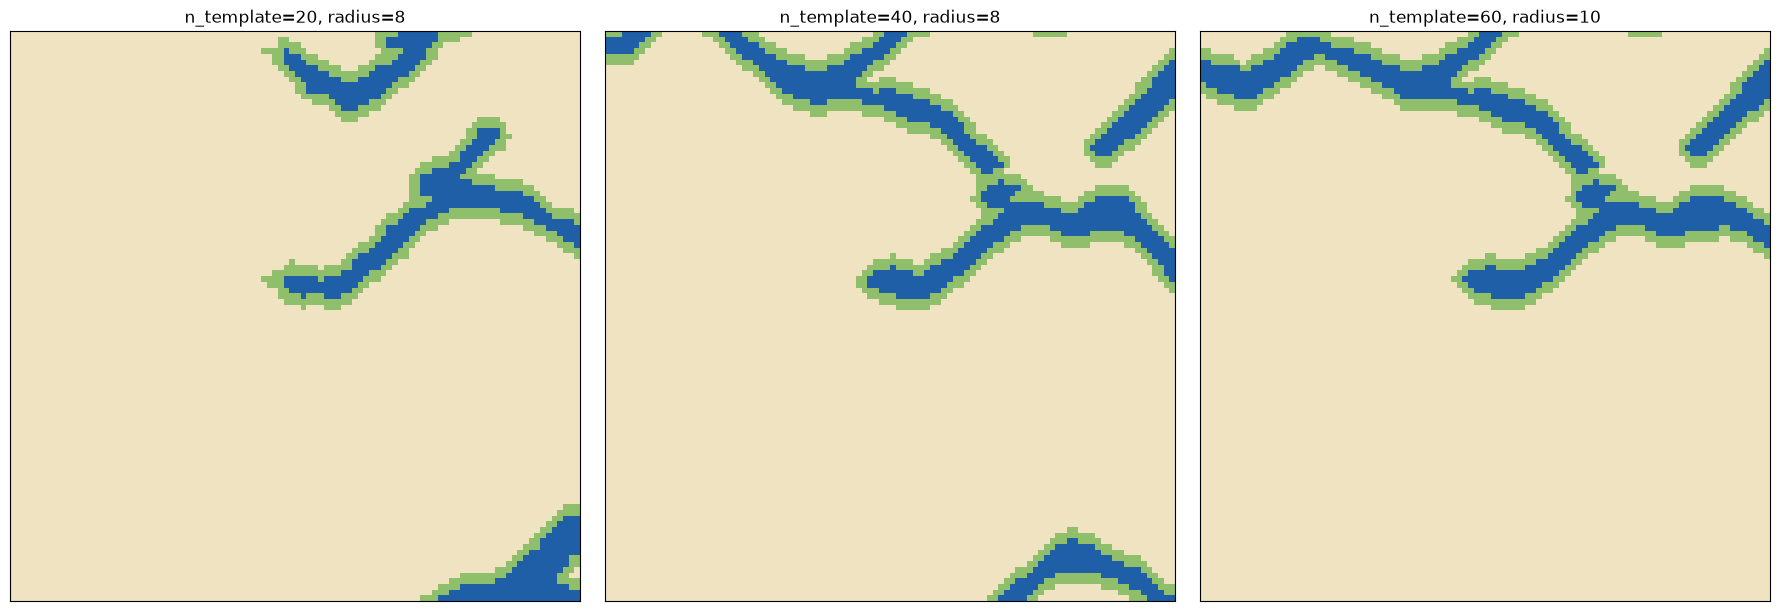

In [4]:
from geolattice.geostatistics.mps.snesim import _template

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (n, r) in zip(axes, [(20, 8), (40, 8), (60, 10)]):
    off = _template(n, r)
    ax.scatter(off[:, 0], off[:, 1], c=np.arange(len(off)), cmap="viridis", s=60)
    ax.scatter([0], [0], marker="x", c="red", s=80)
    ax.set_title(f"n_template = {n}, search_radius = {r}")
    ax.set_aspect("equal")
    ax.set_xlim(-r - 1, r + 1)
    ax.set_ylim(-r - 1, r + 1)
plt.tight_layout()
plt.show()

rows, template_imgs = [], {}
for n, r in [(20, 8), (40, 8), (60, 10)]:
    row, reals = evaluate(f"n_template={n}, radius={r}", n_template=n, search_radius=r, servo=0.0)
    rows.append(row)
    template_imgs[row["setting"]] = reals[0]
rows.append(ref_row)
display(pd.DataFrame(rows).set_index("setting").round(3))
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (k, im_) in zip(axes, template_imgs.items()):
    show(ax, im_, k)
plt.tight_layout()
plt.show()

* **Size and cost.** The pattern table grows with the template: 3,428 unique patterns on the finest grid with 40 nodes, against 1,057 with 20 and 6,064 with 60. The cost per realization grows with it: 0.5, 1.2 and 2.0 s for 8 realizations.
* **Fidelity.** The 20-node template produces the most forbidden floodplain-channel contacts (4.8 per realization) and slightly fewer channel cells (0.093 against the TI's 0.104). It sees too little of the levee around a channel to always enforce it. 40 and 60 nodes are close (2.6 and 2.4 forbidden edges).
* **Noisy measures.** Channel connectivity at 30 cells does not change monotonically with template size. With 8 realizations it is a noisy measure, and the multigrid (next section) has a larger effect on it.

A template of 30-60 nodes is a sound default; the GPU engine supports up to 64.

***
## Multiple Grids

`n_multigrid` from 1 (finest grid only) to 5 (coarsest spacing 16 cells), with the default 40-node template and `servo=0`:

,seconds,patterns per level,forbidden FP-CH edges,pattern dist. (3x3),channel connectivity @30,prop. floodplain,prop. channel,prop. levee
setting,,,,,,,,
n_multigrid=1,0.943,[3428],17.750,0.147,0.000,0.829,0.053,0.118
n_multigrid=2,1.028,"[3428, 5470]",8.375,0.101,0.165,0.779,0.109,0.112
n_multigrid=3,1.154,"[3428, 5470, 15076]",6.875,0.073,0.450,0.817,0.094,0.089
n_multigrid=4,1.178,"[3428, 5470, 15076, 23801]",2.625,0.110,0.757,0.784,0.114,0.101
n_multigrid=5,1.184,"[3428, 5470, 15076, 23801, 28670]",2.875,0.080,0.878,0.794,0.107,0.099
training image,NaN,NaN,0.000,0.000,0.937,0.806,0.104,0.091


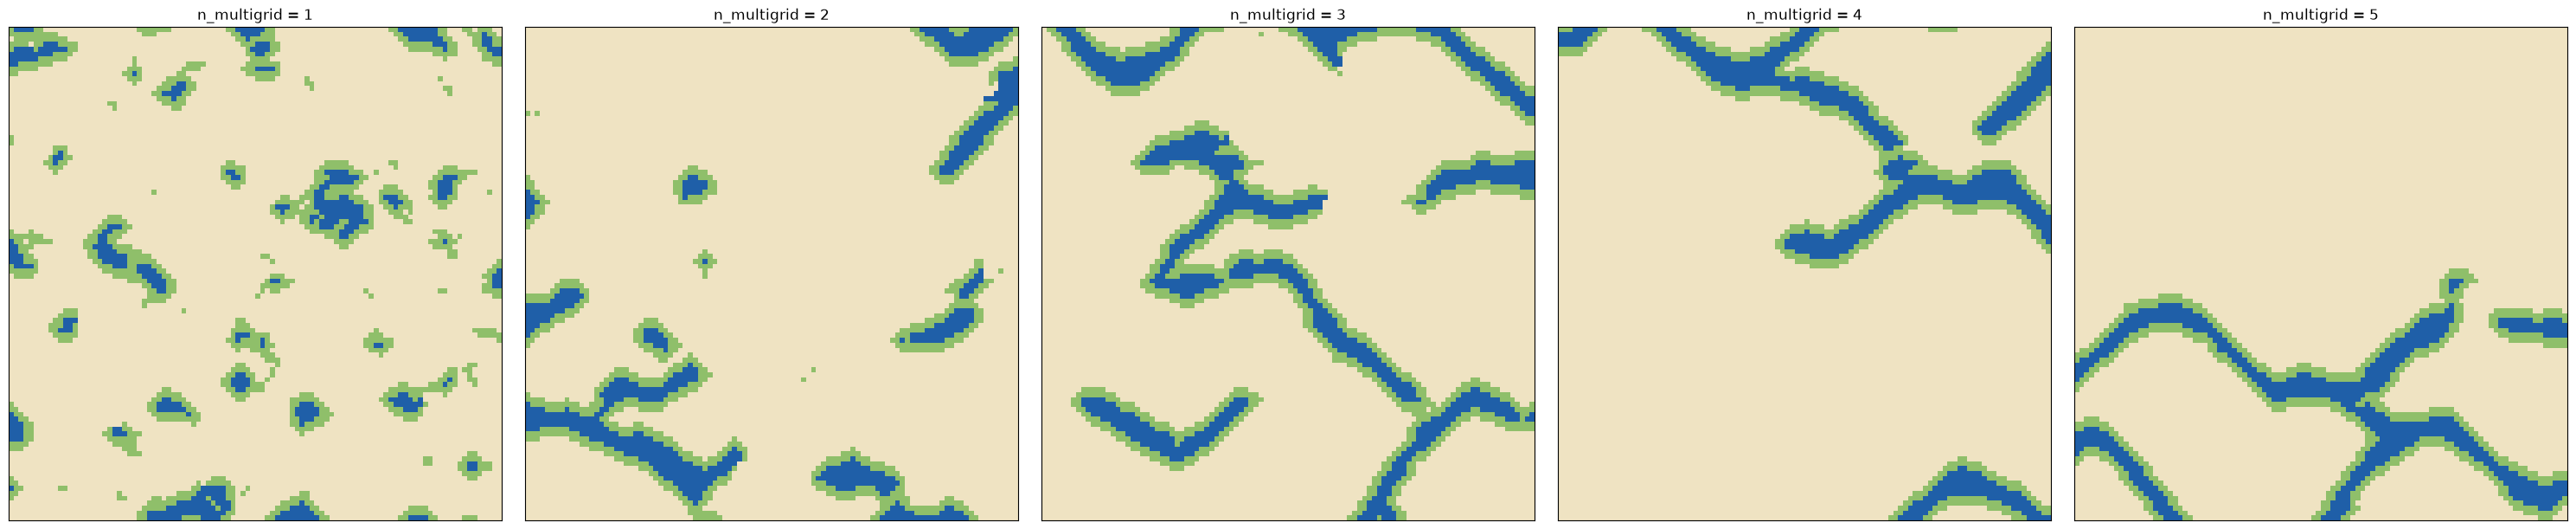

✅ [PASS] multigrid raises channel connectivity (4 levels vs 1)  0.00 -> 0.76


In [5]:
rows, mg_imgs = [], {}
for mg in [1, 2, 3, 4, 5]:
    row, reals = evaluate(f"n_multigrid={mg}", n_multigrid=mg, servo=0.0)
    rows.append(row)
    mg_imgs[mg] = reals[0]
rows.append(ref_row)
mg_table = pd.DataFrame(rows).set_index("setting")
display(mg_table.round(3))
fig, axes = plt.subplots(1, 5, figsize=(30, 6))
for ax, (mg, im_) in zip(axes, mg_imgs.items()):
    show(ax, im_, f"n_multigrid = {mg}")
plt.tight_layout()
plt.show()
record("multigrid raises channel connectivity (4 levels vs 1)",
       "PASS" if mg_table.loc["n_multigrid=4", "channel connectivity @30"] > mg_table.loc["n_multigrid=1", "channel connectivity @30"] + 0.2
       else "FAIL", f"{mg_table.loc['n_multigrid=1', 'channel connectivity @30']:.2f} -> "
                    f"{mg_table.loc['n_multigrid=4', 'channel connectivity @30']:.2f}")

The multigrid is the single most important SNESIM parameter for these channels:

| levels | channel connectivity at 30 cells | forbidden edges |
|---|---|---|
| 1 | 0: channels break into pieces and the channel proportion halves (0.053) | 17.8 |
| 2 | 0.17 | 8.4 |
| 3 | 0.45 | 6.9 |
| 4 | 0.76 | 2.6 |
| 5 | 0.88 (TI 0.94) | 2.9 |

The coarse levels place the channel belts with a template spanning up to 16 × 8 = 128 cells, and the finer levels draw the channel and levee inside them. The extra levels add patterns (28,670 on the coarsest of five) but barely any time: 0.95 s with one level, 1.19 s with five.

***
## Data-Event Reduction: `min_replicates`

How many TI replicates are required before a data event is trusted:

In [6]:
rows = []
for mr in [1, 3, 10, 20]:
    row, _ = evaluate(f"min_replicates={mr}", min_replicates=mr, servo=0.0)
    rows.append(row)
rows.append(ref_row)
mr_table = pd.DataFrame(rows).set_index("setting")
mr_table.drop(columns="patterns per level").round(3)

,seconds,forbidden FP-CH edges,pattern dist. (3x3),channel connectivity @30,prop. floodplain,prop. channel,prop. levee
setting,,,,,,,
min_replicates=1,1.175,0.875,0.106,0.786,0.783,0.116,0.101
min_replicates=3,1.178,2.625,0.110,0.757,0.784,0.114,0.101
min_replicates=10,1.186,5.125,0.107,0.633,0.808,0.101,0.091
min_replicates=20,1.193,11.375,0.104,0.694,0.815,0.098,0.087
training image,NaN,0.000,0.000,0.937,0.806,0.104,0.091


`min_replicates` behaves as Section 2.3 predicts. Requiring more replicates drops more of the outer data-event nodes, and with them the constraints:

| `min_replicates` | forbidden edges | channel connectivity at 30 cells |
|---|---|---|
| 1 | 0.9 | 0.79 |
| 3 (default) | 2.6 | 0.76 |
| 10 | 5.1 | 0.63 |
| 20 | 11.4 | 0.69 |

Proportions shift slightly toward floodplain as constraints are lost. With a 200 × 200 TI, small values work best. Large values only make sense with large TIs, where even big data events have many replicates.

***
## Proportions: Servosystem and Target Proportions

First, the servosystem with the default targets (the TI proportions). Then, **target proportions different from the TI's** (floodplain 0.60, channel 0.25, levee 0.15), a common need when the TI is a conceptual picture but the proportions come from wells or regional knowledge.

,seconds,forbidden FP-CH edges,pattern dist. (3x3),channel connectivity @30,prop. floodplain,prop. channel,prop. levee
setting,,,,,,,
"servo=0.0, TI targets",1.177,2.625,0.110,0.757,0.784,0.114,0.101
"servo=0.5, TI targets",1.205,3.125,0.069,0.814,0.786,0.114,0.100
"servo=0.8, TI targets",1.209,6.000,0.065,0.846,0.778,0.115,0.107
"servo=0.0, targets 0.60/0.25/0.15",1.181,3.000,0.128,0.779,0.767,0.126,0.107
"servo=0.5, targets 0.60/0.25/0.15",1.218,2.750,0.135,0.703,0.709,0.159,0.132
"servo=0.8, targets 0.60/0.25/0.15",1.228,5.125,0.209,0.857,0.638,0.213,0.149
"servo=0.95, targets 0.60/0.25/0.15",1.234,8.625,0.254,0.948,0.601,0.239,0.160
training image,NaN,0.000,0.000,0.937,0.806,0.104,0.091


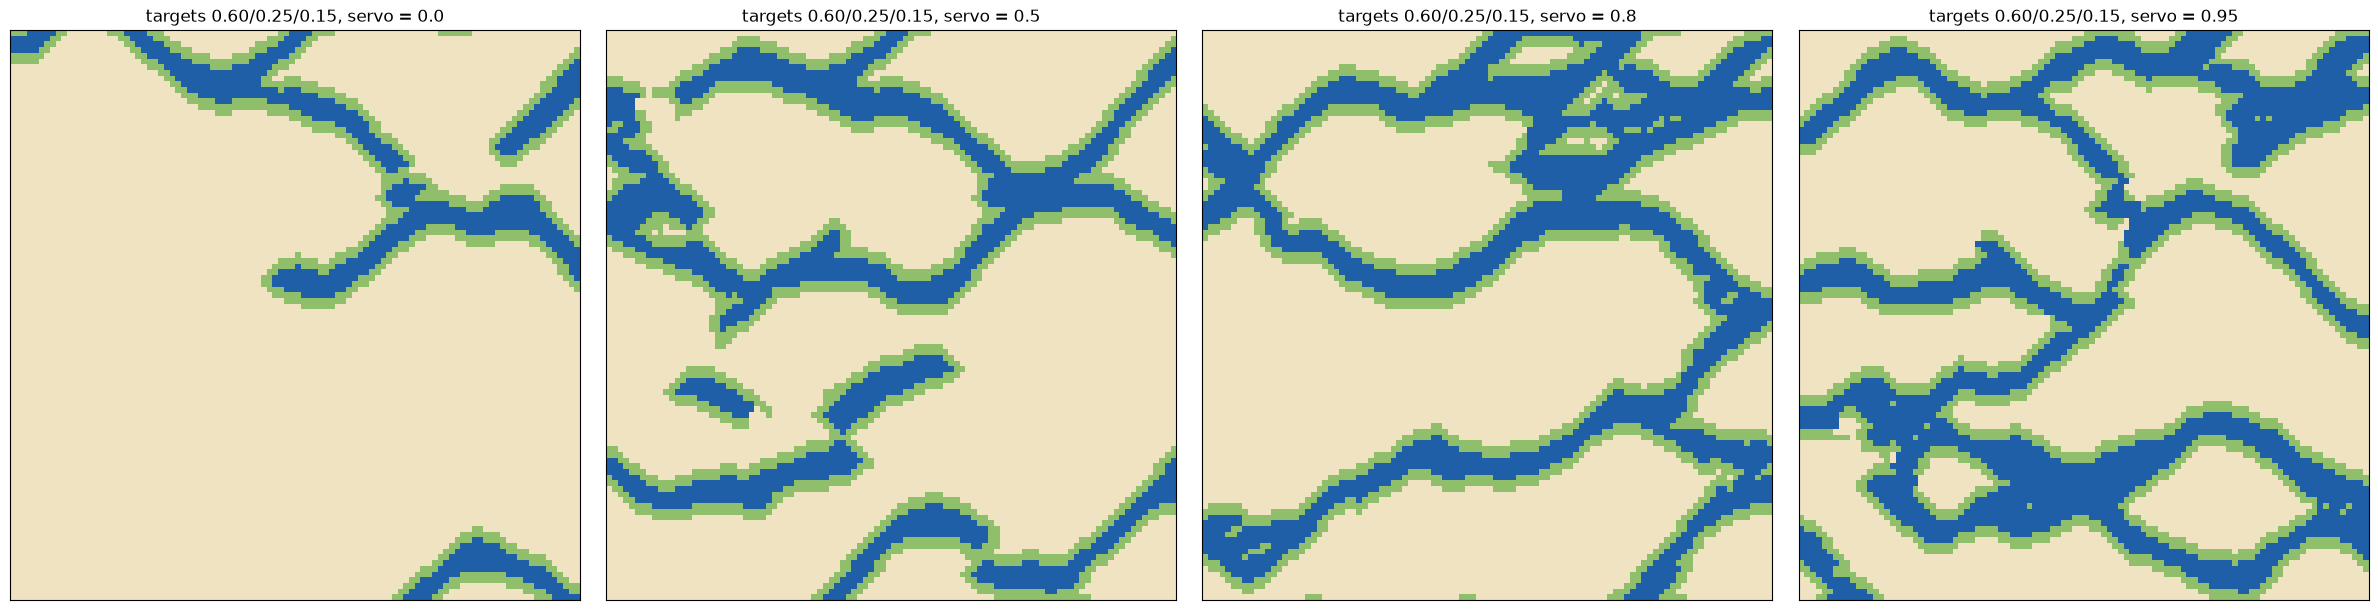

✅ [PASS] servo=0.8 moves channel proportion toward a 0.25 target  channel proportion 0.213 (TI 0.104)


In [7]:
rows = []
for sv in [0.0, 0.5, 0.8]:
    row, _ = evaluate(f"servo={sv}, TI targets", servo=sv)
    rows.append(row)
TARGET = {0.0: 0.60, 1.0: 0.25, 2.0: 0.15}
target_imgs = {}
for sv in [0.0, 0.5, 0.8, 0.95]:
    row, reals = evaluate(f"servo={sv}, targets 0.60/0.25/0.15", servo=sv, target_proportions=TARGET)
    rows.append(row)
    target_imgs[sv] = reals[0]
rows.append(ref_row)
servo_table = pd.DataFrame(rows).set_index("setting").drop(columns="patterns per level")
display(servo_table.round(3))
fig, axes = plt.subplots(1, 4, figsize=(24, 6))
for ax, (sv, im_) in zip(axes, target_imgs.items()):
    show(ax, im_, f"targets 0.60/0.25/0.15, servo = {sv}")
plt.tight_layout()
plt.show()
st = servo_table.loc["servo=0.8, targets 0.60/0.25/0.15"]
record("servo=0.8 moves channel proportion toward a 0.25 target", "PASS" if st["prop. channel"] > 0.18 else "FAIL",
       f"channel proportion {st['prop. channel']:.3f} (TI {np.mean(TI == 1):.3f})")

**With the TI's own proportions as targets**, the realizations already sit close to them (channel 0.114 against 0.104), so the servosystem has little to correct. A strong servosystem still adds forbidden contacts: 2.6 at `servo = 0`, 3.1 at 0.5, 6.0 at 0.8. It also brings the pattern distance down a little (0.110 to 0.065), because the proportions match better.

**With target proportions different from the TI's**, the servosystem is what moves the realizations:

| `servo` | floodplain / channel / levee (target 0.60 / 0.25 / 0.15) |
|---|---|
| 0 | 0.77 / 0.13 / 0.11, essentially the TI's |
| 0.5 | 0.71 / 0.16 / 0.13 |
| 0.8 | 0.64 / 0.21 / 0.15 |
| 0.95 | 0.60 / 0.24 / 0.16, on target |

The price is patterns that drift from the TI. The pattern distance doubles (0.13 to 0.25), the channels widen and merge, and forbidden contacts rise to 8.6 per realization. When the TI's proportions differ from the target area's, the better fix is often a TI with the right proportions. Otherwise use the servosystem moderately and check the patterns.

This behaviour reflects the current additive servosystem (Section 2.3). A change that stops it reviving categories the TI rules out would reduce the forbidden contacts at high `servo`.

***
## Conditioning to Wells

80 wells are drawn at random from the true field. SNESIM (default template, 4 grids, `servo=0`) draws 50 conditional realizations. They are checked for exact conditioning, reproducibility, and equality of `snesim` with the class, and scored against the truth:

* **multiclass Brier score** of the facies probabilities;
* **channel recall** of the most probable map;
* **agreement per realization**;
* forbidden contacts and connectivity.

In [8]:
well_idx = np.random.default_rng(1).choice(len(grid), 80, replace=False)
wells = pd.DataFrame({"X": grid[well_idx, 0], "Y": grid[well_idx, 1], "f": truth[well_idx]})
print("wells per facies:", {f: int((wells.f == k).sum()) for k, f in enumerate(FACIES)})
N_SIM = 50
sn = SNESIM(TI, servo=0.0, use_gpu=USE_GPU).fit(grid, wells, "X", "Y", "f")
t0 = time.perf_counter()
cond = sn.simulate(nsim=N_SIM, seed=2)
print(f"{N_SIM} conditional realizations in {time.perf_counter() - t0:.1f} s")

record("conditional SNESIM: wells honoured in every realization",
       "PASS" if np.all(cond[:, well_idx] == wells.f.to_numpy()[None, :]) else "FAIL")
record("conditional SNESIM: same seed -> identical",
       "PASS" if np.array_equal(SNESIM(TI, servo=0.0, use_gpu=USE_GPU).fit(grid, wells, "X", "Y", "f").simulate(
           nsim=5, seed=2), cond[:5]) else "FAIL")
record("snesim(...) == SNESIM(...).simulate",
       "PASS" if np.array_equal(snesim(grid, wells, "X", "Y", "f", TI, nsim=5, servo=0.0, seed=2, use_gpu=USE_GPU),
                                cond[:5]) else "FAIL")


def score(name, reals):
    r = np.asarray(reals)
    P = np.stack([(r == k).mean(0) for k in range(3)])
    onehot = np.stack([(truth == k).astype(float) for k in range(3)])
    imgs = r.reshape(-1, NX, NY)
    return {"method": name, "Brier": np.mean(((P - onehot) ** 2).sum(0)),
            "channel recall (most probable)": np.mean((P.argmax(0) == 1)[truth == 1]),
            "agreement per realization": np.mean(r == truth[None, :]),
            "forbidden FP-CH edges": np.mean([contacts(x)[0, 1] for x in imgs[:10]]),
            "channel connectivity @30": np.nanmean([connectivity(x, 1, 30, 0)[-1] for x in imgs[:10]])}


uncond = SNESIM(TI, servo=0.0, use_gpu=USE_GPU).fit(grid).simulate(nsim=N_SIM, seed=2)
cond_table = pd.DataFrame([score("unconditional", uncond), score("80 wells", cond)]).set_index("method")
display(cond_table.round(3))

wells per facies: {'floodplain': 50, 'channel': 12, 'levee': 18}


50 conditional realizations in 1.3 s
✅ [PASS] conditional SNESIM: wells honoured in every realization  


✅ [PASS] conditional SNESIM: same seed -> identical  


✅ [PASS] snesim(...) == SNESIM(...).simulate  


,Brier,channel recall (most probable),agreement per realization,forbidden FP-CH edges,channel connectivity @30
method,,,,,
unconditional,0.506,0.00,0.568,1.8,0.891
80 wells,0.421,0.36,0.630,21.1,0.595


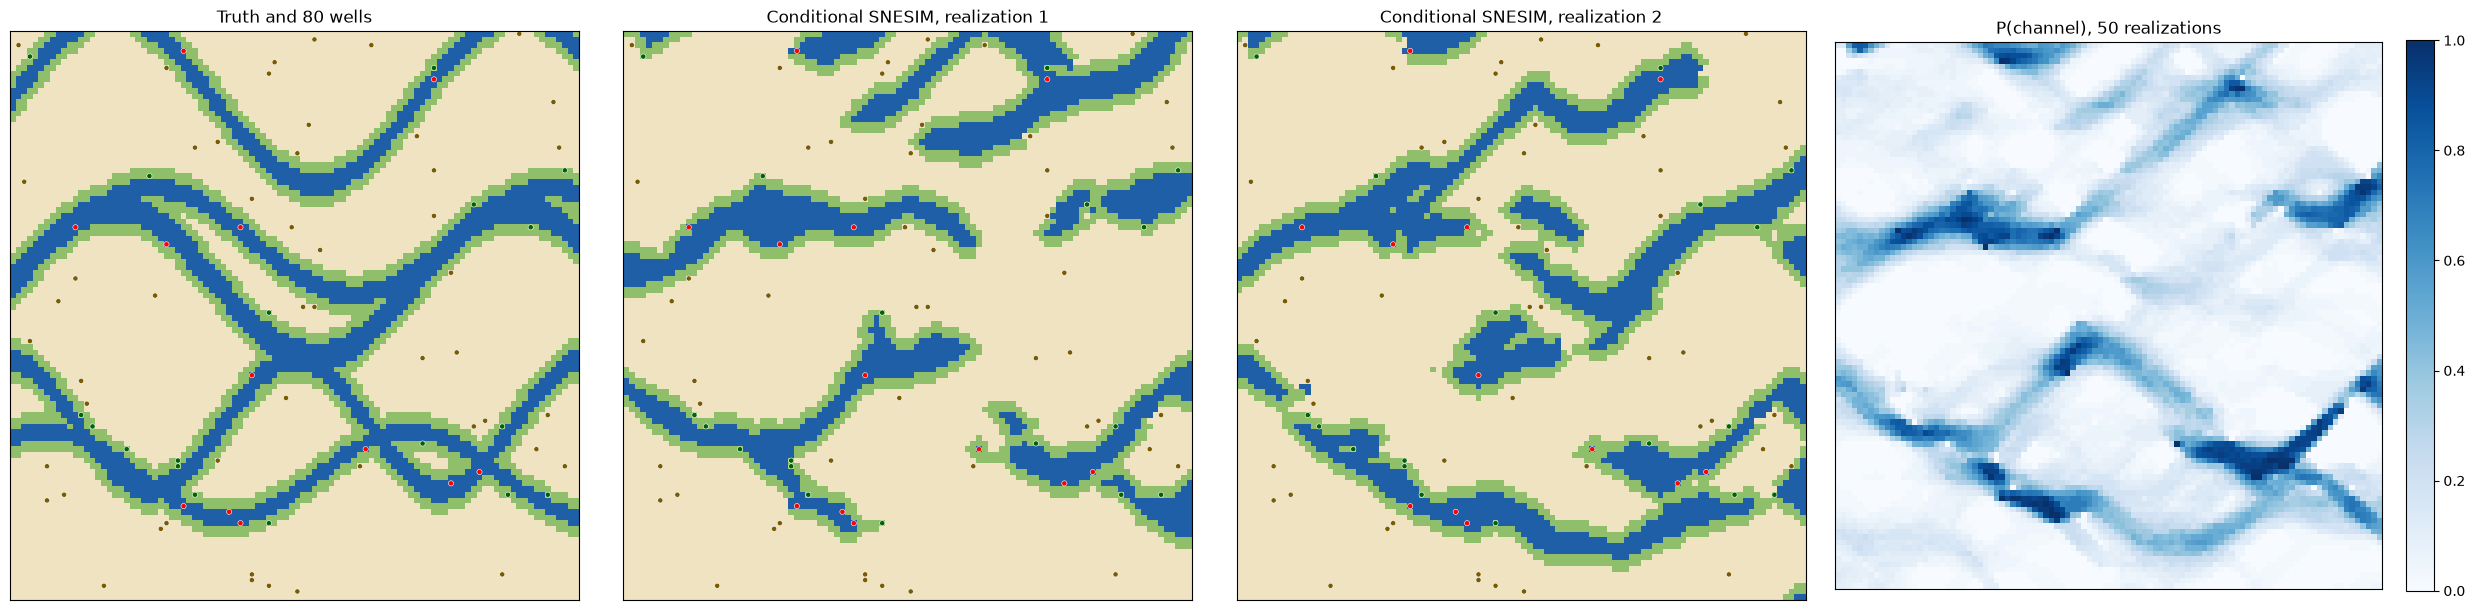

In [9]:
P_cond = np.stack([(cond == k).mean(0) for k in range(3)])
fig, axes = plt.subplots(1, 4, figsize=(25, 6))
show(axes[0], TRUTH, "Truth and 80 wells", wells)
show(axes[1], cond[0].reshape(NX, NY), "Conditional SNESIM, realization 1", wells)
show(axes[2], cond[1].reshape(NX, NY), "Conditional SNESIM, realization 2", wells)
im = axes[3].imshow(P_cond[1].reshape(NX, NY).T, origin="lower", cmap="Blues", vmin=0, vmax=1)
axes[3].set_title(f"P(channel), {N_SIM} realizations")
axes[3].set_xticks([])
axes[3].set_yticks([])
plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

* **Exact conditioning.** The 80 wells are honoured in every realization, and the seed reproduces the realizations.
* **Local accuracy.** Conditioning improves it: the multiclass Brier score falls from 0.51 to 0.42, the most probable map finds 36% of the channel cells, and agreement per realization rises from 0.57 to 0.63. The P(channel) map shows the channels pinned near channel wells and diffuse elsewhere. Only 12 of the 80 wells are in channels.
* **Patterns suffer.** Forbidden contacts rise from 1.8 to 21 per realization, and channel connectivity at 30 cells falls from 0.89 to 0.60. The wells create data events with combinations the TI rarely shows (a channel well next to a floodplain well, or a well inside a predicted levee). Those events are reduced, or force awkward patterns locally.

This conflict between data and TI is normal in MPS. A TI whose patterns are consistent with the data (here, more variable channel widths and spacings) reduces it.

***
## Soft Data and the Tau Model

A **seismic-like** secondary variable is built by blurring the channel indicator (Gaussian filter, $\sigma$ = 3 cells) and adding noise. It responds to channels, but blurs them and cannot tell levee from floodplain. The same operator on the TI gives paired (facies, secondary) values. From those, the soft probabilities $P(s_k \mid y)$ are tabulated in 20 quantile bins of $y$ and looked up on the grid. These are passed to `fit(..., soft=...)`.

`tau_model` itself is shown first on one node, then SNESIM is run with several $\tau$:

| $\tau$ | Meaning |
|---|---|
| (1, 1) | permanence of ratios (default) |
| (1, 0.5) | soft data discounted |
| (1, 2) | soft data emphasized |
| (0, 1) | soft data only; the TI is ignored except through the hard data |

corr(secondary, channel indicator) on the truth: 0.64
tau = (1, 1):  P = [0.005 0.747 0.248]
tau = (1, 0.5):  P = [0.033 0.709 0.258]
tau = (1, 2):  P = [0.    0.742 0.258]
tau = (0, 1):  P = [0.1 0.8 0.1]
tau = (1, 0):  P = [0.2 0.5 0.3]


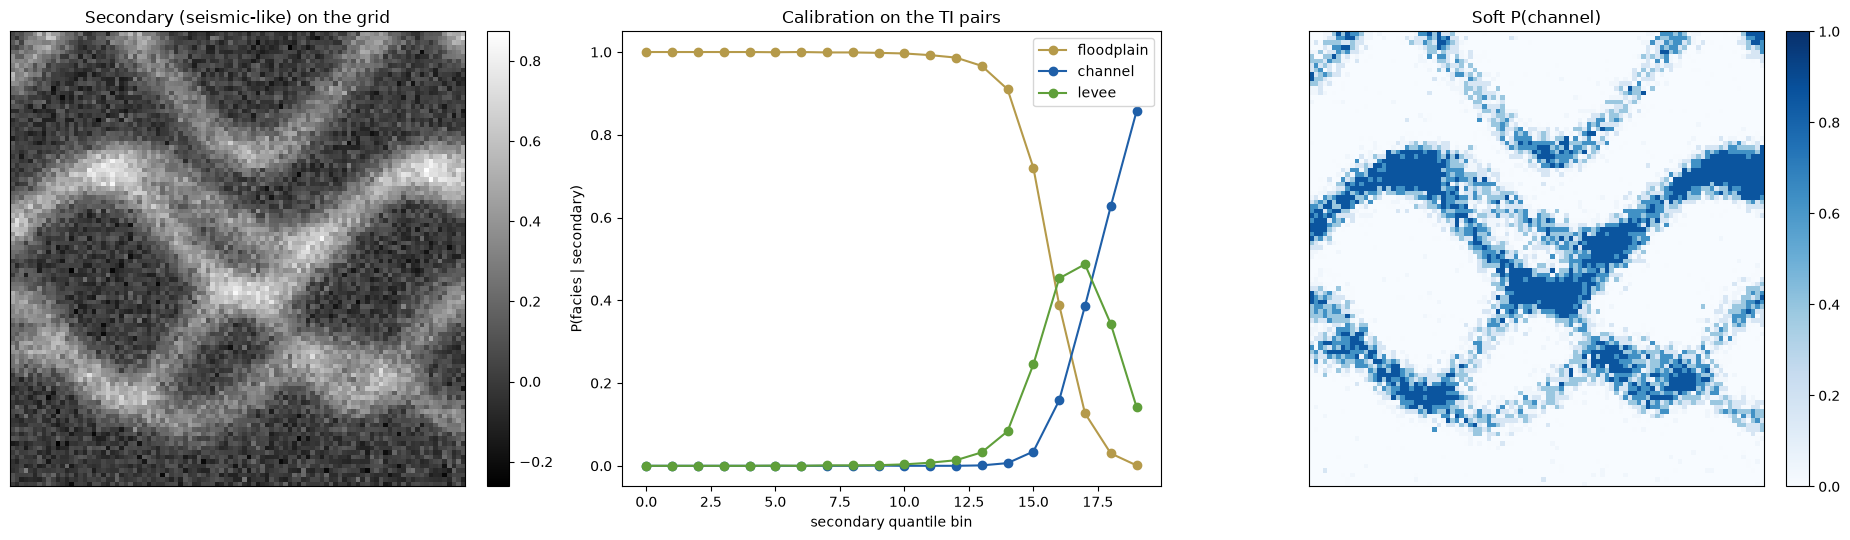

In [10]:
def seismic(img, seed):
    return gaussian_filter((np.asarray(img) == 1).astype(float), 3.0) + np.random.default_rng(seed).normal(0, 0.08, np.shape(img))


Y_TI = seismic(TI, 10)
y_grid = seismic(TRUTH, 11).ravel()
edges = np.quantile(Y_TI, np.linspace(0, 1, 21))
bin_ti = np.clip(np.searchsorted(edges, Y_TI.ravel(), side="right") - 1, 0, 19)
table = np.array([[np.mean(TI.ravel()[bin_ti == b] == k) for k in range(3)] for b in range(20)])
bin_grid = np.clip(np.searchsorted(edges, y_grid, side="right") - 1, 0, 19)
soft = table[bin_grid]                                           # (n_nodes, 3), columns: floodplain, channel, levee
print(f"corr(secondary, channel indicator) on the truth: {np.corrcoef(y_grid, truth == 1)[0, 1]:.2f}")

prior = np.array([np.mean(TI == k) for k in range(3)])
p_ti, p_soft = np.array([0.2, 0.5, 0.3]), np.array([0.1, 0.8, 0.1])
for tau in [(1, 1), (1, 0.5), (1, 2), (0, 1), (1, 0)]:
    print(f"tau = {tau}:  P = {np.round(tau_model(prior, p_ti, p_soft, tau), 3)}")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
im = axes[0].imshow(y_grid.reshape(NX, NY).T, origin="lower", cmap="gray")
axes[0].set_title("Secondary (seismic-like) on the grid")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
for k, c in enumerate(["#b59a4a", "#1f5fa8", "#5f9f3a"]):
    axes[1].plot(np.arange(20), table[:, k], "o-", c=c, label=FACIES[k])
axes[1].set_xlabel("secondary quantile bin")
axes[1].set_ylabel("P(facies | secondary)")
axes[1].set_title("Calibration on the TI pairs")
axes[1].legend()
im = axes[2].imshow(soft[:, 1].reshape(NX, NY).T, origin="lower", cmap="Blues", vmin=0, vmax=1)
axes[2].set_title("Soft P(channel)")
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
for ax in [axes[0], axes[2]]:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

,Brier,channel recall (most probable),agreement per realization,forbidden FP-CH edges,channel connectivity @30
method,,,,,
"80 wells, no soft data",0.421,0.360,0.630,21.1,0.595
"80 wells + soft, tau = (1, 1)",0.294,0.563,0.755,42.3,0.806
"80 wells + soft, tau = (1, 0.5)",0.326,0.488,0.720,14.0,0.717
"80 wells + soft, tau = (1, 2)",0.272,0.589,0.778,26.0,0.636
"80 wells + soft, tau = (0, 1)",0.239,0.696,0.782,1120.7,0.019


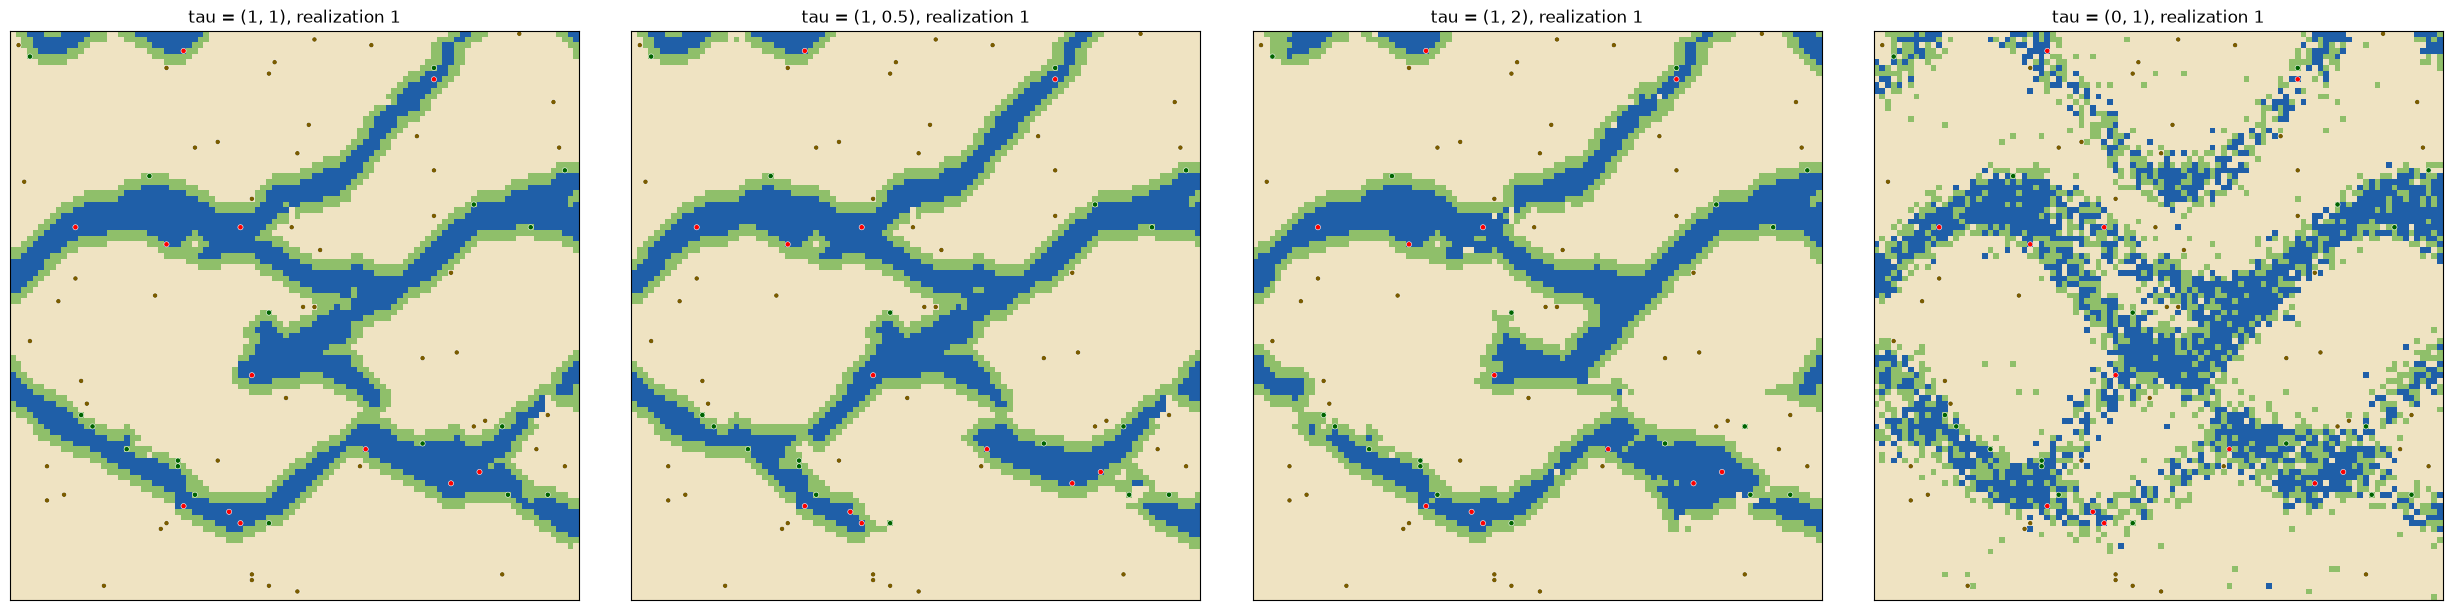

✅ [PASS] soft data (tau = (1,1)) lower the Brier score  0.421 -> 0.294


In [11]:
rows, tau_reals = [score("80 wells, no soft data", cond)], {}
for tau in [(1, 1), (1, 0.5), (1, 2), (0, 1)]:
    sim = SNESIM(TI, servo=0.0, tau=tau, use_gpu=USE_GPU).fit(grid, wells, "X", "Y", "f", soft=soft)
    r = sim.simulate(nsim=N_SIM, seed=2)
    tau_reals[tau] = r
    rows.append(score(f"80 wells + soft, tau = {tau}", r))
tau_table = pd.DataFrame(rows).set_index("method")
display(tau_table.round(3))

fig, axes = plt.subplots(1, 4, figsize=(25, 6))
for ax, (tau, r) in zip(axes, tau_reals.items()):
    show(ax, r[0].reshape(NX, NY), f"tau = {tau}, realization 1", wells)
plt.tight_layout()
plt.show()
t11 = tau_table.loc["80 wells + soft, tau = (1, 1)"]
record("soft data (tau = (1,1)) lower the Brier score", "PASS" if t11.Brier < tau_table.iloc[0].Brier else "FAIL",
       f"{tau_table.iloc[0].Brier:.3f} -> {t11.Brier:.3f}")

* **Soft data help local accuracy a lot.** With $\tau = (1, 1)$, the Brier score falls from 0.42 to 0.29, channel recall from 0.36 to 0.56, and agreement rises from 0.63 to 0.76. Connectivity also improves (0.60 to 0.81), because the soft data place the channels where the wells alone could not.
* **The $\tau$ exponents trade local accuracy against pattern fidelity:**

| $\tau$ | Brier | forbidden contacts | channel connectivity |
|---|---|---|---|
| (1, 0.5): soft discounted | 0.33 | 14 | 0.72 |
| (1, 1) | 0.29 | 42 | 0.81 |
| (1, 2): soft emphasized | 0.27 | 26 | 0.64 |
| (0, 1): TI ignored | 0.24 | 1,121 | 0.02 |

* **Why ignoring the TI fails.** $\tau = (0, 1)$ has the best Brier score but is not a fluvial image any more. Without the TI's patterns, the blurred secondary paints channel blobs straight onto floodplain, with no levees in between and no continuous channels.
* **Choosing $\tau$.** Good local scores are not enough: check the patterns as well. $\tau = (1, 1)$ is a good default here, with large gains in accuracy and connectivity and a moderate rise in forbidden contacts. Discount the soft data ($\tau_2 < 1$) when they are redundant with the wells or the TI.

The single-node example shows the mechanics. With a TI probability of 0.5 and a soft probability of 0.8 for channel, against a prior of 0.10, $\tau = (1, 1)$ gives 0.75. The soft data's odds ratio over the prior multiplies the TI's.

***
## Visualization of Uncertainty

The 50 conditional realizations with wells and soft data, $\tau = (1, 1)$.

### Animated display of realizations

In [12]:
best = tau_reals[(1, 1)]
plt.rcParams["animation.embed_limit"] = 50
fig_anim, ax_anim = plt.subplots(figsize=(7, 7))
im_anim = ax_anim.imshow(best[0].reshape(NX, NY).T, origin="lower", cmap=CMAP, vmin=-0.5, vmax=2.5,
                         interpolation="nearest")
ax_anim.scatter(wells.X, wells.Y, c="k", s=8)
ax_anim.set_xticks([])
ax_anim.set_yticks([])
title_anim = ax_anim.set_title("SNESIM with wells and soft data, realization 1 / 20")


def _update(frame):
    im_anim.set_data(best[frame].reshape(NX, NY).T)
    title_anim.set_text(f"SNESIM with wells and soft data, realization {frame + 1} / 20")
    return im_anim, title_anim


anim = FuncAnimation(fig_anim, _update, frames=20, interval=500, blit=False, repeat=True)
plt.close(fig_anim)
display(HTML(anim.to_jshtml()))

### Facies probability and entropy maps

Probability of each facies over the 50 realizations, and the entropy $H = -\sum_k p_k \ln p_k$ (at most $\ln 3 \approx 1.10$ nats).

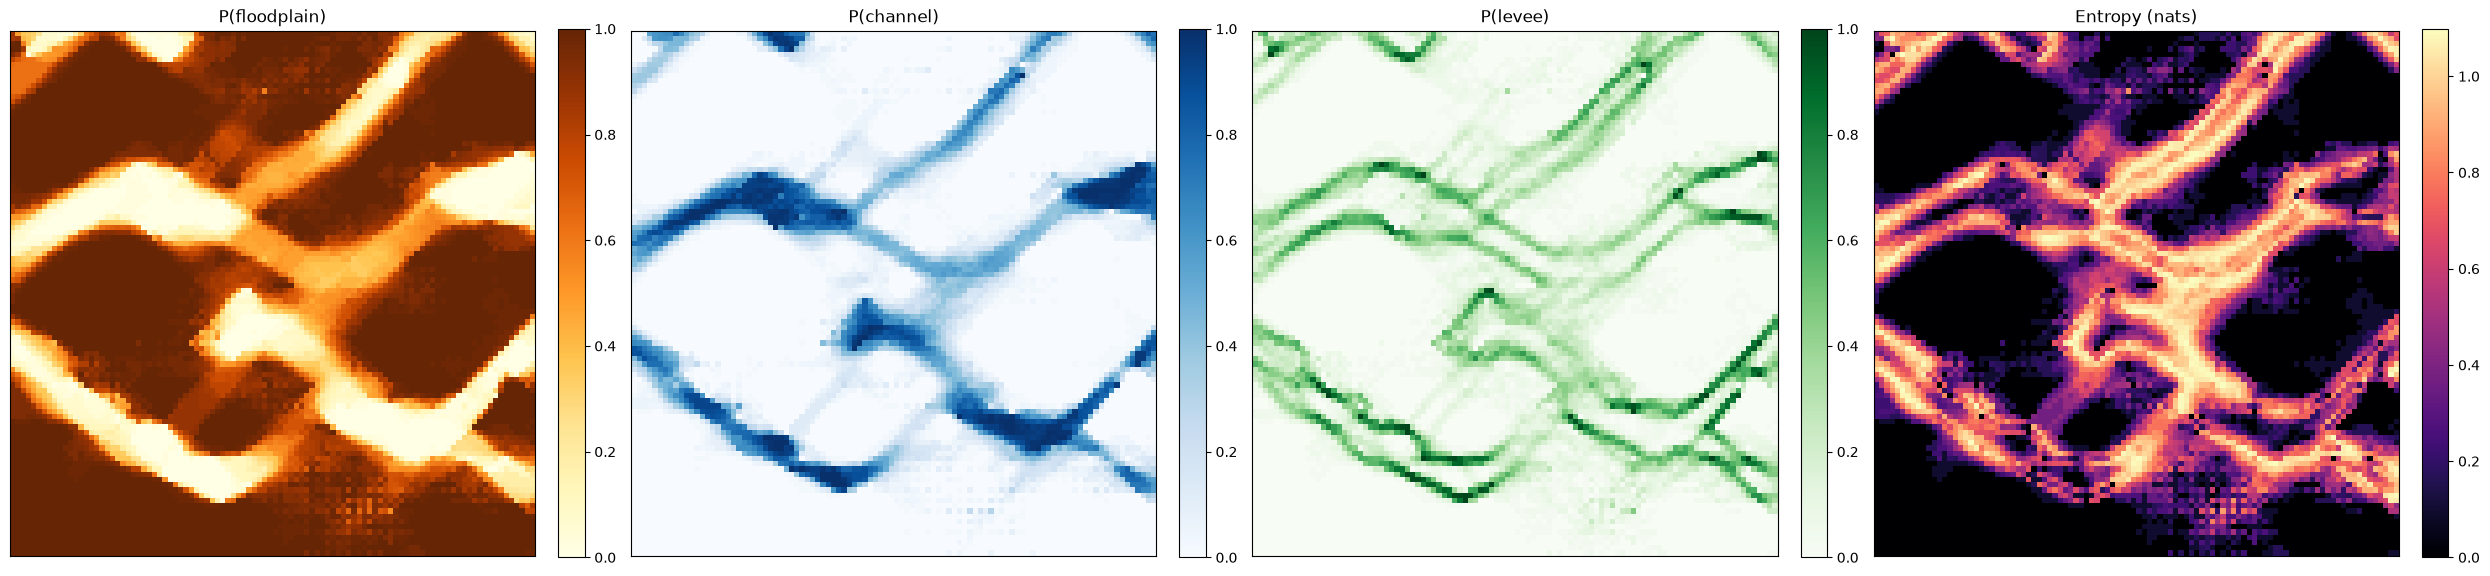

mean entropy 0.33 nats; nodes with one facies at P > 0.9: 59%


In [13]:
P = np.stack([(best == k).mean(0) for k in range(3)])
H = -(np.where(P > 0, P * np.log(np.where(P > 0, P, 1)), 0)).sum(0)
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
for ax, k, cm in zip(axes, range(3), ["YlOrBr", "Blues", "Greens"]):
    im = ax.imshow(P[k].reshape(NX, NY).T, origin="lower", cmap=cm, vmin=0, vmax=1)
    ax.set_title(f"P({FACIES[k]})")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
im = axes[3].imshow(H.reshape(NX, NY).T, origin="lower", cmap="magma", vmin=0, vmax=np.log(3))
axes[3].set_title("Entropy (nats)")
plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()
print(f"mean entropy {H.mean():.2f} nats; nodes with one facies at P > 0.9: {np.mean(P.max(0) > 0.9):.0%}")

Uncertainty concentrates along channel and levee margins: the soft data and wells place the channel belts, but not their exact edges. The floodplain far from channels is nearly certain.

***
## CPU vs GPU Timing

Conditional SNESIM (80 wells, soft data, 4 grids, 40-node template) on the 100 × 100 lattice, for several `nsim`. CPU and GPU realizations are compared exactly.

In [14]:
rows = []
for nsim in [1, 8, 32]:
    row = {"nsim": nsim}
    cpu = SNESIM(TI, servo=0.0, use_gpu=False).fit(grid, wells, "X", "Y", "f", soft=soft)
    t0 = time.perf_counter()
    out_cpu = cpu.simulate(nsim=nsim, seed=3)
    row["CPU (s)"] = time.perf_counter() - t0
    if USE_GPU:
        gpu = SNESIM(TI, servo=0.0, use_gpu=True).fit(grid, wells, "X", "Y", "f", soft=soft)
        gpu.simulate(nsim=1, seed=0)
        t0 = time.perf_counter()
        out_gpu = gpu.simulate(nsim=nsim, seed=3)
        cp.cuda.Device(0).synchronize()
        row["GPU (s)"] = time.perf_counter() - t0
        row["speedup"] = row["CPU (s)"] / row["GPU (s)"]
        row["identical"] = bool(np.array_equal(out_cpu, out_gpu))
    rows.append(row)
timing = pd.DataFrame(rows).set_index("nsim")
display(timing.round(2))
if USE_GPU:
    record("SNESIM GPU = CPU (with soft data)", "PASS" if timing["identical"].all() else "FAIL",
           f"speedup at nsim=32: {timing.loc[32, 'speedup']:.0f}x")

,CPU (s),GPU (s),speedup,identical
nsim,,,,
1,2.81,1.19,2.36,True
8,21.96,1.36,16.20,True
32,87.87,1.42,61.82,True


✅ [PASS] SNESIM GPU = CPU (with soft data)  speedup at nsim=32: 62x


The GPU engine gives **identical** realizations to the CPU engine, with soft data included. The CPU needs about 2.8 s per realization on this 100 × 100 lattice. The GPU time barely grows with `nsim` (1.2 s for one realization, 1.45 s for 32), so the speed-up rises from 2× at one realization to 61× at 32.

***
## Summary and Conclusions

In [15]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,multigrid raises channel connectivity (4 level...,PASS,0.00 -> 0.76
1,servo=0.8 moves channel proportion toward a 0....,PASS,channel proportion 0.213 (TI 0.104)
2,conditional SNESIM: wells honoured in every re...,PASS,
3,conditional SNESIM: same seed -> identical,PASS,
4,snesim(...) == SNESIM(...).simulate,PASS,
5,"soft data (tau = (1,1)) lower the Brier score",PASS,0.421 -> 0.294
6,SNESIM GPU = CPU (with soft data),PASS,speedup at nsim=32: 62x


- **SNESIM** reads the conditional probability of each facies from the frequencies of the same data event in the training image (the single normal equation), stored once in a pattern table.
- **The multigrid matters most** for large structures. Channel connectivity at 30 cells went from 0 with one grid to 0.88 with five (TI 0.94), at almost no extra cost. The **template** (30-60 nodes) and a small **`min_replicates`** (1-3) keep the TI's adjacency rules: forbidden floodplain-channel contacts fell to 0.9 per realization with `min_replicates = 1`.
- **Proportions:** the servosystem barely matters when the TI's proportions are the target. To reach *different* targets, it moved the channel proportion from 0.11 to 0.24 (target 0.25), at the price of patterns that drift from the TI (pattern distance 0.13 → 0.25) and more forbidden contacts.
- **Conditioning** to 80 wells was exact and improved local accuracy (Brier 0.51 → 0.42), but data events the TI rarely shows raised the forbidden contacts (1.8 → 21).
- **Soft data through the tau model** improved local accuracy substantially (Brier 0.42 → 0.29, channel recall 0.36 → 0.56) and restored connectivity. The exponents trade local accuracy against pattern fidelity, and ignoring the TI ($\tau = (0, 1)$) destroys the geology.
- **GPU:** identical realizations, 61× faster at 32 realizations.

### Choosing the options

| Parameter | Guidance from this notebook |
|---|---|
| `n_template`, `search_radius` | 30-60 nodes; larger templates store more patterns and cost more per lookup; the GPU engine allows up to 64 |
| `n_multigrid` | enough levels that the coarsest template spans the largest structure (here 4-5 for 100-cell channels) |
| `min_replicates` | small (1-3) for continuity and fewer forbidden patterns; larger only with large TIs |
| `servo` | 0 when pattern fidelity matters and the TI's proportions are acceptable; up to 0.8 to reach different targets, checking forbidden patterns |
| `target_proportions` | from wells or regional knowledge when the TI's proportions are not representative (with `servo` > 0) |
| `soft`, `tau` | calibrate soft probabilities on TI pairs; $\tau = (1, 1)$ is a sound default; check that $\tau_2 > 1$ does not break the patterns |
| `use_gpu` | `True` for many realizations: identical results, much faster |

***
## References

| Reference | Used for |
|---|---|
| Strebelle, S. (2002). Conditional simulation of complex geological structures using multiple-point statistics. *Mathematical Geology* 34, 1-21. | SNESIM: search tree, multigrid, servosystem |
| Guardiano, F.B. & Srivastava, R.M. (1993). Multivariate geostatistics: beyond bivariate moments. In Soares, A. (ed.), *Geostatistics Tróia '92*, 133-144. Kluwer. | The single normal equation |
| Straubhaar, J., Renard, P., Mariethoz, G., Froidevaux, R. & Besson, O. (2011). An improved parallel multiple-point algorithm using a list approach. *Mathematical Geosciences* 43, 305-328. | List-based pattern storage |
| Journel, A.G. (2002). Combining knowledge from diverse sources: an alternative to traditional data independence hypotheses. *Mathematical Geology* 34, 573-596. | The tau model |
| Liu, Y. (2006). Using the Snesim program for multiple-point statistical simulation. *Computers & Geosciences* 32, 1544-1563. | Practical parameter choices |
| Remy, N., Boucher, A. & Wu, J. (2009). *Applied Geostatistics with SGeMS*. Cambridge University Press. | SNESIM in practice, servosystem, soft data |
| Mariethoz, G. & Caers, J. (2014). *Multiple-Point Geostatistics: Stochastic Modeling with Training Images*. Wiley-Blackwell. | MPS diagnostics |